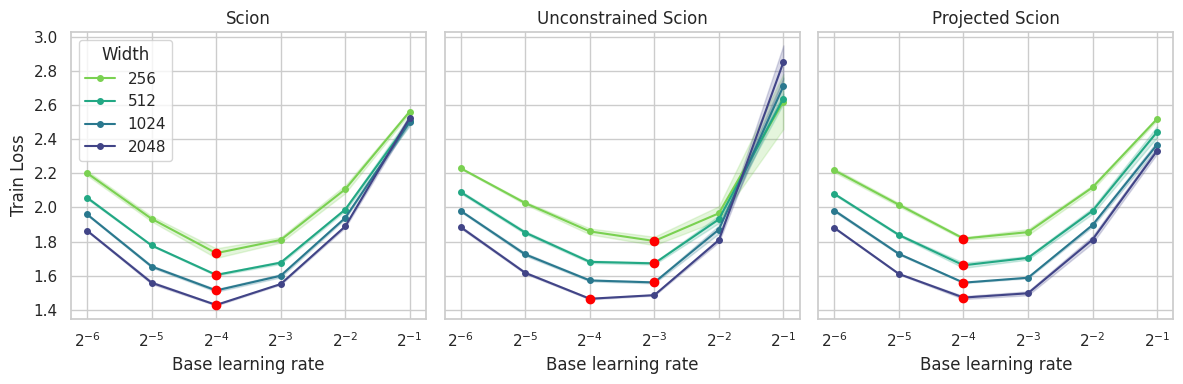

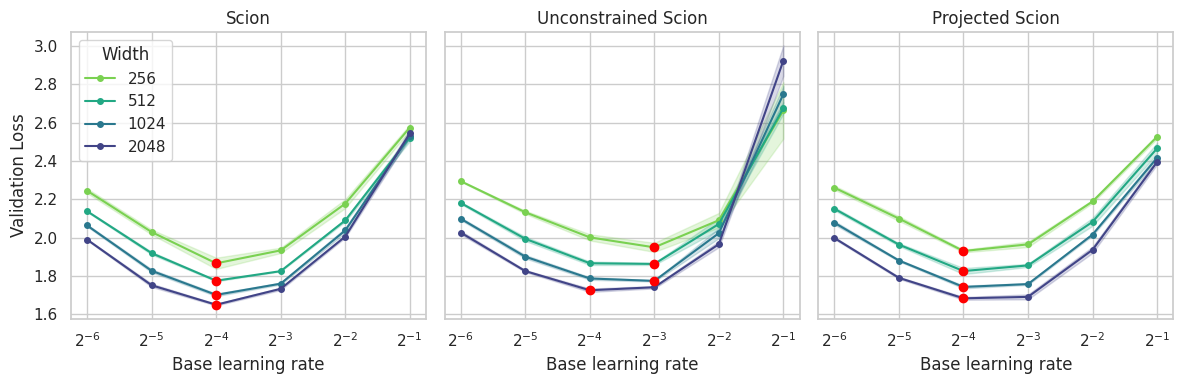

In [ ]:
import os
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# --- Configuration ---
sns.set(style='whitegrid')
dataset = 'shakespeare_char' 
scion_methods = ['constrained_scion', 'unconstrained_scion', 'projected_scion']
loss_datasets = ['train', 'val']

METHOD_MAP = {
    'unconstrained_scion': 'Unconstrained Scion',
    'projected_scion': 'Projected Scion',
    'constrained_scion': 'Scion'
}

# Parameters
seeds = [2, 3, 4]
widths = [256, 512, 1024, 2048]
depths = [3]
lrs = [
        0.5, 0.25,
        0.125, 0.0625, 0.03125, 0.015625, 
        # 0.0078125, 0.00390625
       ]
extra = 'Spectral'
out_path_suffix = "out_depthfactor_2L_block_size_1024_batchsize_32_lrdecayiters_600000/"

for loss_dataset in loss_datasets:
    fig, axes = plt.subplots(1, len(scion_methods), figsize=(12, 4), sharey=True)
    axs = axes.flatten()

    for i, method_key in enumerate(scion_methods):
        ax = axs[i]
        method_str = METHOD_MAP[method_key]
        palette = sns.color_palette("viridis", n_colors=len(widths))
        
        optimal_lrs = []
        optimal_losses = []

        for w_idx, width in enumerate(widths):
            mean_losses = []
            sem_losses = []
            lrs_to_plot = []

            for lr in lrs:
                run_losses = []
                for seed in seeds:
                    for depth in depths:
                        job_name = f'first_layer{extra}_width{width}_depth{depth}_seed{seed}_lr{lr:.20f}'.rstrip('0')
                        csv_path = os.path.join(
                            f'mup_examples/widthtransfer_lr_{dataset}/', 
                            method_key, out_path_suffix, 
                            f'hptransferwidth_alpha_skipconnection_0_{job_name}', 'log.csv'
                        )

                        if os.path.exists(csv_path):
                            df = pd.read_csv(csv_path)
                            # val = df[f'{loss_dataset}/loss'].min()
                            val = df[f'{loss_dataset}/loss'].values[-1]
                            # val = df[f'{loss_dataset}/loss'].ewm(alpha=0.9).mean().values[-1]
                            run_losses.append(val)
                        
                        else:
                            print(f"missing path: {csv_path}")
                
                if run_losses:
                    mean_losses.append(np.mean(run_losses))
                    sem_losses.append(np.std(run_losses, ddof=1) / np.sqrt(len(run_losses)) if len(run_losses) > 1 else 0)
                    lrs_to_plot.append(lr)

            if mean_losses:
                color = palette[len(widths) - w_idx - 1]
                ax.plot(lrs_to_plot, mean_losses, label=width, color=color, marker='o', markersize=4)
                if any(sem_losses):
                    ax.fill_between(lrs_to_plot, np.array(mean_losses)-sem_losses, np.array(mean_losses)+sem_losses, color=color, alpha=0.2)
                
                opt_idx = np.argmin(mean_losses)
                optimal_lrs.append(lrs_to_plot[opt_idx])
                optimal_losses.append(mean_losses[opt_idx])

        ax.plot(optimal_lrs, optimal_losses, color='red', linestyle='none', marker='o')
        ax.set_xscale('log', base=2)
        ax.set_title(method_str)
        ax.set_xlabel('Base learning rate')
        
        if i == 0:
            if loss_dataset=="val":
                ax.set_ylabel(f'Validation Loss')
            else:
                ax.set_ylabel(f'{loss_dataset.capitalize()} Loss')
            ax.legend(title='Width')
        else:
            ax.set_ylabel('') 

    plt.tight_layout()
    plt.savefig(f"GPT_{dataset}_width_transfer_scion_uscion_pscion_{loss_dataset}.pdf")
    plt.show()